In [1]:
#import and configuration 
import os
import json
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../data/3D_Medical_Scan"

with open(os.path.join(DATA_DIR, "dataset.json"), "r") as f:
    dataset_info = json.load(f)

print("Dataset:", dataset_info["name"])
print("Training scans:", dataset_info["numTraining"])
print("Test scans:", dataset_info["numTest"])
print("Labels:", dataset_info["labels"])

# Load one CT scan and its segmentation mask
image_path = os.path.join(DATA_DIR, "imagesTr", "lung_053.nii.gz")
mask_path = os.path.join(DATA_DIR, "labelsTr", "lung_053.nii.gz")

image = nib.load(image_path)
mask = nib.load(mask_path)

print("\nCT shape:", image.shape)
print("Mask shape:", mask.shape)
print("CT data type:", image.get_data_dtype())
print("Mask unique labels:", np.unique(mask.get_fdata()))

Dataset: Lung
Training scans: 63
Test scans: 32
Labels: {'0': 'background', '1': 'cancer'}

CT shape: (512, 512, 252)
Mask shape: (512, 512, 252)
CT data type: float32
Mask unique labels: [0. 1.]


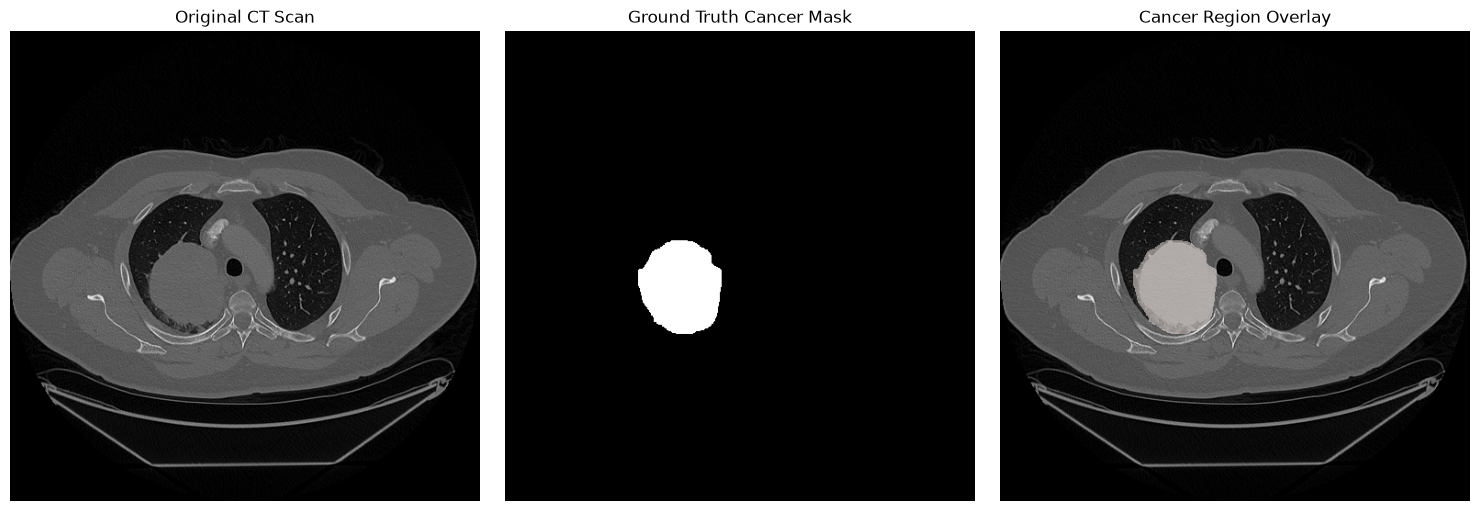

In [2]:
# Visualization: CT scan and cancer mask

filename = "lung_053.nii.gz"

ct_path = os.path.join(DATA_DIR, "imagesTr", filename)
mask_path = os.path.join(DATA_DIR, "labelsTr", filename)

# Load original NIfTI objects
ct_nii = nib.load(ct_path)
mask_nii = nib.load(mask_path)

slice_idx = 181

# Load only selected 2D slices
ct_slice = np.asarray(ct_nii.dataobj[:, :, slice_idx])
mask_slice = np.asarray(mask_nii.dataobj[:, :, slice_idx])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[0].set_title("Original CT Scan")

axes[1].imshow(mask_slice.T, cmap="gray", origin="lower")
axes[1].set_title("Ground Truth Cancer Mask")

axes[2].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[2].imshow(
    np.ma.masked_where(mask_slice.T == 0, mask_slice.T),
    cmap="Reds",
    alpha=0.5,
    origin="lower"
)
axes[2].set_title("Cancer Region Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
#Visualize resampled CT and mask

slice_idx = 181

resampled_ct = image[0].cpu().numpy()
resampled_mask = mask[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(resampled_ct[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[0].set_title("Resampled CT")

axes[1].imshow(resampled_mask[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[1].set_title("Resampled Cancer Mask")

axes[2].imshow(resampled_ct[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[2].imshow(
    np.ma.masked_where(
        resampled_mask[:, :, slice_idx].T == 0,
        resampled_mask[:, :, slice_idx].T
    ),
    cmap="Reds",
    alpha=0.5,
    origin="lower"
)
axes[2].set_title("Resampled Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

TypeError: Cannot slice image objects; consider using `img.slicer[slice]` to generate a sliced image (see documentation for caveats) or slicing image array data with `img.dataobj[slice]` or `img.get_fdata()[slice]`

In [16]:
#Volume-Level Train/Validation Split (Stratified by Lesion Size)
import pandas as pd
from sklearn.model_selection import train_test_split


df = pd.DataFrame(
    lesion_counts,
    columns=["filename", "cancer_voxels"]
)


df["lesion_group"] = pd.qcut(
    df["cancer_voxels"],
    q=3,
    labels=["small", "medium", "large"]
)


train_df, val_df = train_test_split(
    df,
    test_size=13,
    random_state=42,
    stratify=df["lesion_group"]
)


train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)


assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)


os.makedirs("../processed", exist_ok=True)

train_df.to_csv(
    "../processed/segmentation_train.csv",
    index=False
)

val_df.to_csv(
    "../processed/segmentation_validation.csv",
    index=False
)

print("Training volumes:", len(train_df))
print("Validation volumes:", len(val_df))

print("\nTraining lesion distribution:")
print(train_df["lesion_group"].value_counts())

print("\nValidation lesion distribution:")
print(val_df["lesion_group"].value_counts())

print("\nAverage cancer voxels:")
print("Train:", int(train_df["cancer_voxels"].mean()))
print("Validation:", int(val_df["cancer_voxels"].mean()))

print("\nSplit saved successfully.")

Training volumes: 50
Validation volumes: 13

Training lesion distribution:
lesion_group
medium    17
large     17
small     16
Name: count, dtype: int64

Validation lesion distribution:
lesion_group
small     5
medium    4
large     4
Name: count, dtype: int64

Average cancer voxels:
Train: 30549
Validation: 18294

Split saved successfully.


In [4]:
# 3D_Segmentation Traning Config
import random
import numpy as np
import torch


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


TRAIN_CSV = "../processed/segmentation_train.csv"
VAL_CSV = "../processed/segmentation_validation.csv"

# Patch configuration
PATCH_SIZE = (64, 64, 64)

POSITIVE_PATCHES_PER_VOLUME = 2
NEGATIVE_PATCHES_PER_VOLUME = 2

PATCHES_PER_VOLUME = (
    POSITIVE_PATCHES_PER_VOLUME
    + NEGATIVE_PATCHES_PER_VOLUME
)

TOTAL_TRAIN_PATCHES = 50 * PATCHES_PER_VOLUME


BATCH_SIZE = 1
NUM_WORKERS = 0


TARGET_SPACING = (1.0, 1.0, 1.25)
CT_MIN = -1000
CT_MAX = 1000

print("Patch size:", PATCH_SIZE)
print("Patches per volume:", PATCHES_PER_VOLUME)
print("Training patches per epoch:", TOTAL_TRAIN_PATCHES)
print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

Patch size: (64, 64, 64)
Patches per volume: 4
Training patches per epoch: 200
Batch size: 1
Workers: 0


In [28]:
# cache builder 
import os
import gc
import time
import numpy as np
import pandas as pd
import torch

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Spacingd
)


train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)


TRAIN_CACHE = "../processed/segmentation_train_cache"
VAL_CACHE = "../processed/segmentation_val_cache"

os.makedirs(TRAIN_CACHE, exist_ok=True)
os.makedirs(VAL_CACHE, exist_ok=True)


preprocess = Compose([
    LoadImaged(
        keys=["image", "label"],
        image_only=True,
        dtype=np.float32
    ),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(
        keys=["image", "label"],
        axcodes="RAS"
    ),
    Spacingd(
        keys=["image", "label"],
        pixdim=TARGET_SPACING,
        mode=("bilinear", "nearest")
    )
])


def cache_volumes(dataframe, cache_dir, split_name):

    start_time = time.time()
    completed = 0
    skipped = 0

    for filename in dataframe["filename"]:

        stem = filename.replace(".nii.gz", "")

        ct_path = os.path.join(
            cache_dir, stem + "_ct.npy"
        )

        mask_path = os.path.join(
            cache_dir, stem + "_mask.npy"
        )

        # Skip already completed scans
        if os.path.exists(ct_path) and os.path.exists(mask_path):
            skipped += 1
            continue

        image_path = os.path.join(
            DATA_DIR, "imagesTr", filename
        )

        label_path = os.path.join(
            DATA_DIR, "labelsTr", filename
        )

        if not os.path.exists(image_path):
            raise FileNotFoundError(image_path)

        if not os.path.exists(label_path):
            raise FileNotFoundError(label_path)

        scan_start = time.time()

        
        data = preprocess({
            "image": image_path,
            "label": label_path
        })

      
        ct = data["image"].squeeze(0).cpu().numpy()
        np.clip(ct, CT_MIN, CT_MAX, out=ct)
        ct -= CT_MIN
        ct /= (CT_MAX - CT_MIN)

        
        mask = (
            data["label"].squeeze(0).cpu().numpy()
        ).astype(np.uint8)

        
        assert ct.shape == mask.shape
        assert np.isfinite(ct).all()
        assert ct.min() >= 0 and ct.max() <= 1
        assert set(np.unique(mask)).issubset({0, 1})

       
        temp_ct = ct_path + ".tmp.npy"
        temp_mask = mask_path + ".tmp.npy"

        np.save(temp_ct, ct)
        np.save(temp_mask, mask)

        os.replace(temp_ct, ct_path)
        os.replace(temp_mask, mask_path)

        completed += 1

        print(
            f"{split_name}: {stem} | "
            f"Shape: {ct.shape} | "
            f"Time: {time.time() - scan_start:.1f}s"
        )

        del data, ct, mask
        gc.collect()

    elapsed = time.time() - start_time

    print(f"\n{split_name} cache completed.")
    print("Newly processed:", completed)
    print("Already cached:", skipped)
    print("Time:", round(elapsed / 60, 2), "minutes")



cache_volumes(train_df, TRAIN_CACHE, "TRAIN")
cache_volumes(val_df, VAL_CACHE, "VALIDATION")

print("\nBoth cache operations finished.")


nvImageCodec is not available; skipping pydicom decoder plugin registration.


TRAIN: lung_042 | Shape: (375, 375, 249) | Time: 6.6s
TRAIN: lung_037 | Shape: (400, 400, 251) | Time: 6.9s
TRAIN: lung_015 | Shape: (420, 420, 277) | Time: 10.2s
TRAIN: lung_074 | Shape: (320, 320, 295) | Time: 9.6s
TRAIN: lung_043 | Shape: (394, 394, 257) | Time: 6.2s
TRAIN: lung_001 | Shape: (355, 355, 243) | Time: 7.7s
TRAIN: lung_064 | Shape: (360, 360, 247) | Time: 6.9s
TRAIN: lung_055 | Shape: (420, 420, 241) | Time: 8.6s
TRAIN: lung_006 | Shape: (500, 500, 284) | Time: 22.9s
TRAIN: lung_022 | Shape: (431, 431, 242) | Time: 12.5s
TRAIN: lung_025 | Shape: (410, 410, 300) | Time: 10.9s
TRAIN: lung_080 | Shape: (316, 316, 226) | Time: 9.9s
TRAIN: lung_061 | Shape: (440, 440, 210) | Time: 9.1s
TRAIN: lung_047 | Shape: (402, 402, 509) | Time: 22.2s
TRAIN: lung_020 | Shape: (347, 347, 251) | Time: 8.3s
TRAIN: lung_034 | Shape: (460, 460, 295) | Time: 12.3s
TRAIN: lung_086 | Shape: (400, 400, 266) | Time: 8.9s
TRAIN: lung_003 | Shape: (480, 480, 287) | Time: 11.8s
TRAIN: lung_053 | Sha

In [29]:
#verification of complete cache

import os
import numpy as np
import pandas as pd

def verify_cache(dataframe, cache_dir, split_name):

    results = []
    errors = []

    for filename in dataframe["filename"]:

        stem = filename.replace(".nii.gz", "")

        ct_path = os.path.join(
            cache_dir, stem + "_ct.npy"
        )
        mask_path = os.path.join(
            cache_dir, stem + "_mask.npy"
        )

        if not os.path.exists(ct_path) or not os.path.exists(mask_path):
            errors.append(f"Missing files: {stem}")
            continue

        ct = np.load(ct_path, mmap_mode="r")
        mask = np.load(mask_path, mmap_mode="r")

        valid = (
            ct.shape == mask.shape
            and ct.dtype == np.float32
            and mask.dtype == np.uint8
            and np.isfinite(ct).all()
            and ct.min() >= 0
            and ct.max() <= 1
            and set(np.unique(mask)).issubset({0, 1})
            and np.count_nonzero(mask) > 0
        )

        if not valid:
            errors.append(f"Invalid data: {stem}")

        results.append({
            "filename": stem,
            "shape": ct.shape,
            "cancer_voxels": int(np.count_nonzero(mask)),
            "cache_size_MB": round(
                (os.path.getsize(ct_path)
                 + os.path.getsize(mask_path)) / (1024 ** 2), 2
            ),
            "valid": valid
        })

        del ct, mask

    print(f"\n{split_name} verification")
    print("Expected:", len(dataframe))
    print("Verified:", len(results))
    print("Errors:", len(errors))

    if errors:
        print("Problems:", errors)

    return results, errors


train_results, train_errors = verify_cache(
    train_df, TRAIN_CACHE, "TRAIN"
)

val_results, val_errors = verify_cache(
    val_df, VAL_CACHE, "VALIDATION"
)

all_errors = train_errors + val_errors

verification_df = pd.DataFrame(
    train_results + val_results
)

verification_df.to_csv(
    "../outputs/metrics/segmentation_cache_verification.csv",
    index=False
)

print("\nTotal verified:", len(verification_df))
print("Total errors:", len(all_errors))
print("Total cache size (MB):",
      round(verification_df["cache_size_MB"].sum(), 2))

assert len(verification_df) == 63
assert len(all_errors) == 0

print("\nALL CACHE FILES VERIFIED SUCCESSFULLY!")




TRAIN verification
Expected: 50
Verified: 50
Errors: 0

VALIDATION verification
Expected: 13
Verified: 13
Errors: 0

Total verified: 63
Total errors: 0
Total cache size (MB): 13109.27

ALL CACHE FILES VERIFIED SUCCESSFULLY!


In [24]:
#LungPatchDataset

class LungPatchDataset(Dataset):

    def __init__(
        self,
        dataframe,
        cache_dir,
        positive_patches=2,
        negative_patches=2
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.positive_patches = positive_patches
        self.negative_patches = negative_patches
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.dataframe)

    def get_patch(self, ct, mask, center):

        starts = [
            max(0, min(
                int(center[i]) - PATCH_SIZE[i] // 2,
                ct.shape[i] - PATCH_SIZE[i]
            ))
            for i in range(3)
        ]

        slices = tuple(
            slice(starts[i], starts[i] + PATCH_SIZE[i])
            for i in range(3)
        )

        ct_patch = ct[slices]
        mask_patch = mask[slices]

        return {
            "image": torch.from_numpy(
                np.array(ct_patch, dtype=np.float32, copy=True)
            ).unsqueeze(0),

            "label": torch.from_numpy(
                np.array(mask_patch, dtype=np.float32, copy=True)
            ).unsqueeze(0)
        }

    def sample_positive(self, ct, mask):

        positive_coords = np.argwhere(mask > 0)

        if len(positive_coords) == 0:
            raise ValueError("No cancer voxels found.")

        patches = []

        for _ in range(self.positive_patches):

            center = positive_coords[
                self.rng.integers(len(positive_coords))
            ]

            patch = self.get_patch(ct, mask, center)

            if patch["label"].sum().item() == 0:
                raise RuntimeError("Positive patch contains no cancer.")

            patches.append(patch)

        return patches

    def sample_negative(self, ct, mask):

        patches = []

        for _ in range(self.negative_patches):

            for _ in range(5000):

                center = [
                    self.rng.integers(size)
                    for size in ct.shape
                ]

                x, y, z = center

                if ct[x, y, z] <= 0.02:
                    continue

                if mask[x, y, z] != 0:
                    continue

                patch = self.get_patch(ct, mask, center)

                if patch["label"].sum().item() != 0:
                    continue

                # Reject mostly-air patches
                tissue_fraction = (
                    patch["image"] > 0.05
                ).float().mean().item()

                if tissue_fraction < 0.10:
                    continue

                patches.append(patch)
                break

            else:
                raise RuntimeError(
                    "Could not find a suitable negative patch."
                )

        return patches

    def __getitem__(self, index):

        filename = self.dataframe.iloc[index]["filename"]
        stem = filename.removesuffix(".nii.gz")

        ct = np.load(
            os.path.join(self.cache_dir, stem + "_ct.npy"),
            mmap_mode="r"
        )

        mask = np.load(
            os.path.join(self.cache_dir, stem + "_mask.npy"),
            mmap_mode="r"
        )

        positive = self.sample_positive(ct, mask)
        negative = self.sample_negative(ct, mask)

        del ct, mask

        return positive + negative

In [6]:
# 3D_UNET_MODEL_ARCHITECTURE
import torch
from monai.networks.nets import UNet

DEVICE = torch.device("cpu")

model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=1,
    channels=(8, 16, 32, 64),
    strides=(2, 2, 2),
    num_res_units=2,
    norm="INSTANCE"
).to(DEVICE)

total_params = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model: 3D U-Net")
print("Device:", DEVICE)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Model: 3D U-Net
Device: cpu
Total parameters: 297,122
Trainable parameters: 297,122


In [7]:
#loss function
from monai.losses import DiceFocalLoss

criterion = DiceFocalLoss(
    sigmoid=True,
    lambda_dice=1.0,
    lambda_focal=1.0,
    gamma=2.0
)

print("Loss function:", criterion)

Loss function: DiceFocalLoss(
  (dice): DiceLoss()
  (focal): FocalLoss()
)


In [8]:
#optimizers config
import torch.optim as optim

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 1e-05


In [27]:
#LungPatchDataset
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader


class LungPatchDataset(Dataset):

    def __init__(
        self,
        dataframe,
        cache_dir,
        positive_patches=2,
        negative_patches=2
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.positive_patches = positive_patches
        self.negative_patches = negative_patches
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.dataframe)

    def get_patch(self, ct, mask, center):

        starts = [
            max(
                0,
                min(
                    int(center[i]) - PATCH_SIZE[i] // 2,
                    ct.shape[i] - PATCH_SIZE[i]
                )
            )
            for i in range(3)
        ]

        slices = tuple(
            slice(starts[i], starts[i] + PATCH_SIZE[i])
            for i in range(3)
        )

        ct_patch = ct[slices]
        mask_patch = mask[slices]

        return {
            "image": torch.from_numpy(
                np.array(ct_patch, dtype=np.float32, copy=True)
            ).unsqueeze(0),

            "label": torch.from_numpy(
                np.array(mask_patch, dtype=np.float32, copy=True)
            ).unsqueeze(0)
        }

    def sample_positive(self, ct, mask):

        positive_coords = np.argwhere(mask > 0)

        if len(positive_coords) == 0:
            raise ValueError("No cancer voxels found.")

        patches = []

        for _ in range(self.positive_patches):

            center = positive_coords[
                self.rng.integers(len(positive_coords))
            ]

            patch = self.get_patch(ct, mask, center)

            if patch["label"].sum().item() == 0:
                raise RuntimeError(
                    "Positive patch contains no cancer."
                )

            patches.append(patch)

        return patches

    def sample_negative(self, ct, mask):

        patches = []

        for _ in range(self.negative_patches):

            for _ in range(5000):

                center = [
                    self.rng.integers(size)
                    for size in ct.shape
                ]

                x, y, z = center

               
                if not (0.05 <= ct[x, y, z] <= 0.30):
                    continue

                if mask[x, y, z] != 0:
                    continue

                patch = self.get_patch(ct, mask, center)

                # Entire patch must be cancer-free
                if patch["label"].sum().item() != 0:
                    continue

               
                lung_fraction = (
                    (patch["image"] >= 0.05) &
                    (patch["image"] <= 0.30)
                ).float().mean().item()

                if lung_fraction < 0.15:
                    continue

                patches.append(patch)
                break

            else:
                raise RuntimeError(
                    "Could not find a suitable negative patch "
                    "after 5000 attempts."
                )

        return patches

    def __getitem__(self, index):

        filename = self.dataframe.iloc[index]["filename"]
        stem = filename.removesuffix(".nii.gz")

        ct = np.load(
            os.path.join(
                self.cache_dir,
                stem + "_ct.npy"
            ),
            mmap_mode="r"
        )

        mask = np.load(
            os.path.join(
                self.cache_dir,
                stem + "_mask.npy"
            ),
            mmap_mode="r"
        )

        positive = self.sample_positive(ct, mask)
        negative = self.sample_negative(ct, mask)

        del ct, mask

        return positive + negative



train_dataset = LungPatchDataset(
    train_df,
    TRAIN_CACHE,
    positive_patches=1,
    negative_patches=3
)

val_dataset = LungPatchDataset(
    val_df,
    VAL_CACHE,
    positive_patches=2,
    negative_patches=2
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print("Training volumes:", len(train_dataset))
print("Validation volumes:", len(val_dataset))
print("Training patches per volume: 1 positive + 3 negative")
print("Validation patches per volume: 2 positive + 2 negative")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training volumes: 50
Validation volumes: 13
Training patches per volume: 1 positive + 3 negative
Validation patches per volume: 2 positive + 2 negative
Training batches: 50
Validation batches: 13


In [30]:
# training loop 
import time
import torch

NUM_EPOCHS = 5


start_epoch = len(train_losses)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

  
    model.train()
    running_train_loss = 0.0
    train_steps = 0

    for patch_group in train_loader:

        for patch in patch_group:

            x = patch["image"].to(DEVICE)
            y = patch["label"].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item()
            train_steps += 1

    epoch_train_loss = running_train_loss / train_steps
    train_losses.append(epoch_train_loss)

   
    model.eval()
    running_val_loss = 0.0
    val_steps = 0

    with torch.no_grad():

        for patch_group in val_loader:

            for patch in patch_group:

                x = patch["image"].to(DEVICE)
                y = patch["label"].to(DEVICE)

                logits = model(x)
                loss = criterion(logits, y)

                running_val_loss += loss.item()
                val_steps += 1

    epoch_val_loss = running_val_loss / val_steps
    val_losses.append(epoch_val_loss)

    elapsed = time.time() - epoch_start

    print(
        f"Epoch [{start_epoch + epoch + 1}/{start_epoch + NUM_EPOCHS}] "
        f"| Train Loss: {epoch_train_loss:.4f} "
        f"| Val Loss: {epoch_val_loss:.4f} "
        f"| Time: {elapsed:.2f}s"
    )

Epoch [6/10] | Train Loss: 1.0818 | Val Loss: 1.0464 | Time: 171.34s
Epoch [7/10] | Train Loss: 1.0480 | Val Loss: 1.0052 | Time: 91.17s
Epoch [8/10] | Train Loss: 1.0193 | Val Loss: 0.9904 | Time: 88.38s
Epoch [9/10] | Train Loss: 1.0074 | Val Loss: 0.9725 | Time: 91.00s
Epoch [10/10] | Train Loss: 0.9995 | Val Loss: 0.9656 | Time: 88.56s


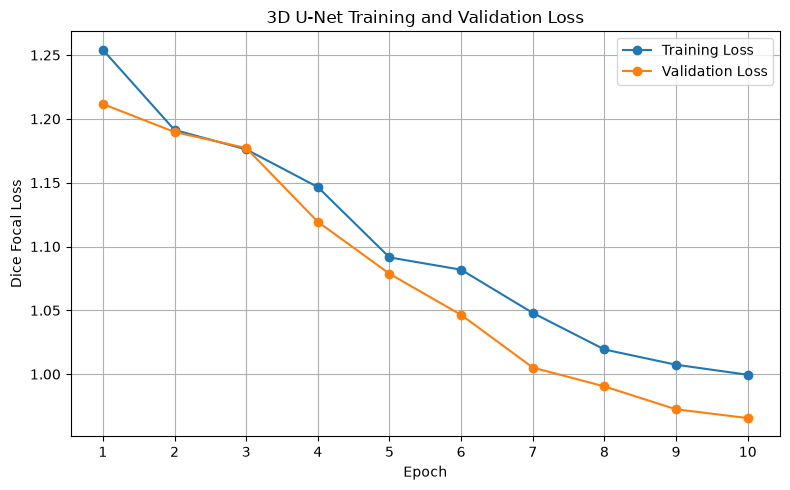

In [31]:
#Training and Validation Loss Graph
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Dice Focal Loss")
plt.title("3D U-Net Training and Validation Loss")

plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [53]:
#Save 3D U-Net Checkpoint
import os
import torch

os.makedirs("../outputs/models", exist_ok=True)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": NUM_EPOCHS,
    "train_losses": train_losses,
    "val_losses": val_losses,
    "patch_size": PATCH_SIZE,
    "target_spacing": TARGET_SPACING
}

torch.save(
    checkpoint,
    "../outputs/models/3d_unet_lung.pth"
)

print("3D U-Net checkpoint saved successfully!")

3D U-Net checkpoint saved successfully!


In [32]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": len(train_losses),
    "train_losses": train_losses,
    "val_losses": val_losses,
    "patch_size": PATCH_SIZE,
    "target_spacing": TARGET_SPACING
}, CHECKPOINT_PATH)

print("Checkpoint saved:", CHECKPOINT_PATH)
print("Completed epochs:", len(train_losses))

Checkpoint saved: ../outputs/models/3d_unet_lung.pth
Completed epochs: 10


In [15]:
#laoding trained checkpoint
import torch

CHECKPOINT_PATH = "../outputs/models/3d_unet_lung.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

train_losses = checkpoint["train_losses"]
val_losses = checkpoint["val_losses"]

print("Checkpoint loaded successfully!")
print("Completed epochs:", checkpoint["epochs"])
print("Training loss:", train_losses[-1])
print("Validation loss:", val_losses[-1])

Checkpoint loaded successfully!
Completed epochs: 5
Training loss: 1.0914715617895125
Validation loss: 1.0786715963712106


In [34]:
#full-volume inference
import torch
import time
from monai.inferers import sliding_window_inference

model.eval()

val_image = val_image.to(DEVICE)

start_time = time.time()

with torch.no_grad():
    val_logits = sliding_window_inference(
        inputs=val_image,
        roi_size=PATCH_SIZE,
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

val_prob = torch.sigmoid(val_logits)
val_pred = (val_prob >= 0.5).float()

print("Inference time:", round(time.time() - start_time, 2), "seconds")
print("Predicted cancer voxels:", int(val_pred.sum().item()))

Inference time: 21.98 seconds
Predicted cancer voxels: 1636233


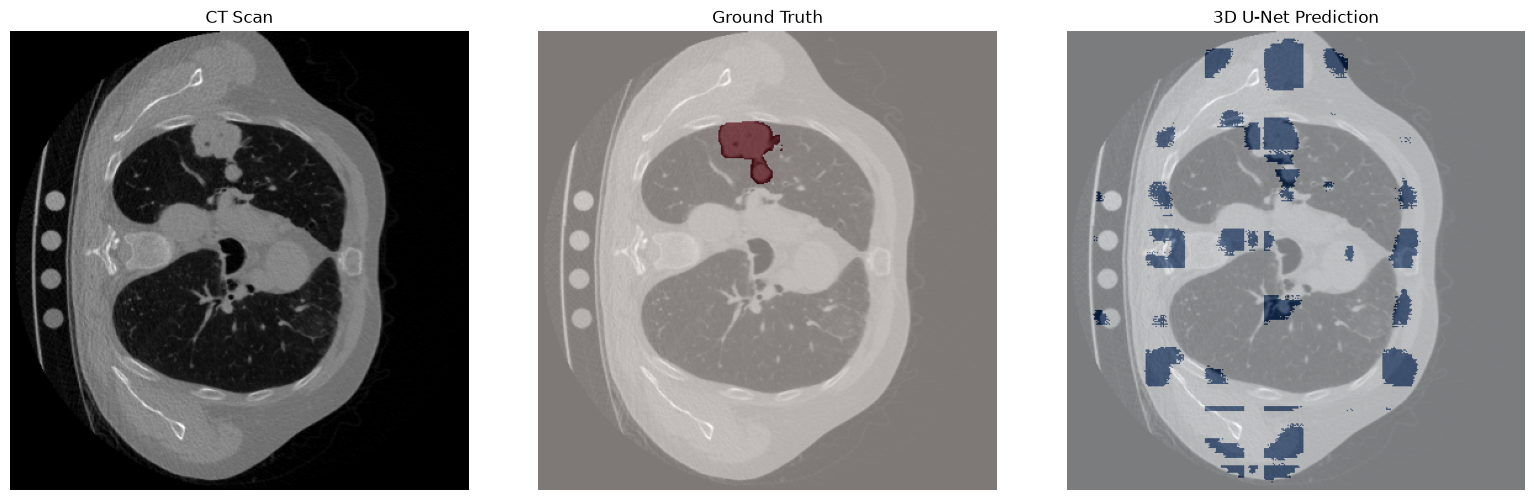

In [41]:
#Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(ct[:, :, slice_idx], cmap="gray")
axes[0].set_title("CT Scan")

axes[1].imshow(ct[:, :, slice_idx], cmap="gray")
axes[1].imshow(gt[:, :, slice_idx], cmap="Reds", alpha=0.5)
axes[1].set_title("Ground Truth")

axes[2].imshow(ct[:, :, slice_idx], cmap="gray")
axes[2].imshow(pred[:, :, slice_idx], cmap="Blues", alpha=0.5)
axes[2].set_title("3D U-Net Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
#Calculate evaluation metrics
from sklearn.metrics import confusion_matrix

y_true = val_mask.cpu().numpy().ravel().astype(int)
y_pred = val_pred.cpu().numpy().ravel().astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)

print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)
print("Dice:", round(dice, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

TP: 16878
FP: 1619355
FN: 16095
TN: 33635592
Dice: 0.0202
Precision: 0.0103
Recall: 0.5119


In [53]:
#evalution metric
import os
import time
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from monai.inferers import sliding_window_inference

cache_dir = Path("../processed/segmentation_val_cache")
output_dir = Path("../outputs/metrics")
output_dir.mkdir(parents=True, exist_ok=True)

model.eval()
results = []

ct_files = sorted(cache_dir.glob("*_ct.npy"))

start_total = time.time()

for idx, ct_file in enumerate(ct_files, 1):

    volume_name = ct_file.name.replace("_ct.npy", "")
    mask_file = cache_dir / f"{volume_name}_mask.npy"

    print(f"\n[{idx}/{len(ct_files)}] Evaluating {volume_name}")

    
    ct_array = np.load(ct_file).astype(np.float32)
    mask_array = np.load(mask_file).astype(np.uint8)

    val_image = torch.from_numpy(ct_array).unsqueeze(0).unsqueeze(0).to(DEVICE)
    val_mask = torch.from_numpy(mask_array).unsqueeze(0).unsqueeze(0).to(DEVICE)

    
    start_time = time.time()

    with torch.no_grad():
        logits = sliding_window_inference(
            inputs=val_image,
            roi_size=PATCH_SIZE,
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        prediction = (torch.sigmoid(logits) >= 0.5)

    
    target = val_mask > 0

    tp = int((prediction & target).sum().item())
    fp = int((prediction & ~target).sum().item())
    fn = int((~prediction & target).sum().item())
    tn = int((~prediction & ~target).sum().item())

    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    results.append({
        "Volume": volume_name,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Inference_Time_sec": round(time.time() - start_time, 2)
    })

    print(
        f"Dice: {dice:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f}"
    )

    
    del val_image, val_mask, logits, prediction
    del ct_array, mask_array


results_df = pd.DataFrame(results)

print("\nPer-volume evaluation:")
display(results_df)


print("\nAverage validation metrics:")
print(results_df[["Dice", "Precision", "Recall"]].mean())


results_df.to_csv(
    output_dir / "segmentation_validation_13_volumes.csv",
    index=False
)

print("\nSaved:", output_dir / "segmentation_validation_13_volumes.csv")
print("Total evaluation time:", round(time.time() - start_total, 2), "seconds")


[1/13] Evaluating lung_014
Dice: 0.0204 | Precision: 0.0104 | Recall: 0.7065

[2/13] Evaluating lung_018
Dice: 0.0027 | Precision: 0.0014 | Recall: 0.5224

[3/13] Evaluating lung_026
Dice: 0.0035 | Precision: 0.0018 | Recall: 0.1229

[4/13] Evaluating lung_033
Dice: 0.0053 | Precision: 0.0027 | Recall: 0.2220

[5/13] Evaluating lung_044
Dice: 0.0000 | Precision: 0.0000 | Recall: 0.0020

[6/13] Evaluating lung_045
Dice: 0.0017 | Precision: 0.0009 | Recall: 0.3886

[7/13] Evaluating lung_049
Dice: 0.0019 | Precision: 0.0010 | Recall: 0.3466

[8/13] Evaluating lung_057
Dice: 0.0000 | Precision: 0.0000 | Recall: 0.0048

[9/13] Evaluating lung_058
Dice: 0.0000 | Precision: 0.0000 | Recall: 0.0000

[10/13] Evaluating lung_065
Dice: 0.0202 | Precision: 0.0103 | Recall: 0.5119

[11/13] Evaluating lung_069
Dice: 0.0000 | Precision: 0.0000 | Recall: 0.0000

[12/13] Evaluating lung_083
Dice: 0.0000 | Precision: 0.0000 | Recall: 0.0000

[13/13] Evaluating lung_093
Dice: 0.0006 | Precision: 0.0003

,Volume,Dice,Precision,Recall,TP,FP,FN,TN,Inference_Time_sec
0,lung_014,0.020423,0.010361,0.706524,17673,1687973,7341,40885013,23.95
1,lung_018,0.002696,0.001351,0.522406,3544,2619025,3240,50226991,34.91
2,lung_026,0.003502,0.001776,0.122864,2200,1236400,15706,34905694,23.34
3,lung_033,0.005266,0.002665,0.221982,5847,2188464,20493,43472796,30.51
4,lung_044,0.000018,0.000009,0.002001,20,2224277,9975,52167328,30.49
5,lung_045,0.001714,0.000859,0.388595,1983,2307439,3120,46281058,25.98
6,lung_049,0.001927,0.000966,0.346629,1347,1393123,2539,36316591,24.15
7,lung_057,0.000024,0.000012,0.004768,18,1467486,3757,34208739,20.31
8,lung_058,0.000000,0.000000,0.000000,0,1995330,643,44468027,25.40
9,lung_065,0.020223,0.010315,0.511873,16878,1619355,16095,33635592,20.72



Average validation metrics:
Dice         0.004338
Precision    0.002201
Recall       0.233448
dtype: float64

Saved: ..\outputs\metrics\segmentation_validation_13_volumes.csv
Total evaluation time: 381.44 seconds


In [49]:
#Generating  3D Grad-CAM
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


DEVICE = torch.device("cpu")

ct = torch.as_tensor(val_image, dtype=torch.float32).to(DEVICE)
mask = torch.as_tensor(val_mask, dtype=torch.float32).to(DEVICE)

if ct.ndim == 4:
    ct = ct.unsqueeze(0)

if mask.ndim == 4:
    mask = mask.unsqueeze(0)


tumor_coords = torch.nonzero(mask[0, 0] > 0)

if len(tumor_coords) == 0:
    raise ValueError("No tumor found in validation mask.")

center = tumor_coords.float().mean(dim=0).long().tolist()



patch_size = 64
D, H, W = ct.shape[2:]

starts = [
    max(0, min(center[i] - patch_size // 2,
               [D, H, W][i] - patch_size))
    for i in range(3)
]

z, y, x = starts

ct_patch = ct[:, :, z:z+64, y:y+64, x:x+64]
mask_patch = mask[:, :, z:z+64, y:y+64, x:x+64]

print("CT patch:", ct_patch.shape)
print("Mask patch:", mask_patch.shape)


target_layer = model.model[1].submodule[1].submodule[1].submodule

activations = {}

def forward_hook(module, input, output):
    activations["features"] = output

handle = target_layer.register_forward_hook(forward_hook)

model.eval()
model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = model(ct_patch)

    
    tumor_region = mask_patch[0, 0] > 0

    target_score = logits[0, 0][tumor_region].mean()

    features = activations["features"]

    gradients = torch.autograd.grad(
        outputs=target_score,
        inputs=features
    )[0]

 
    weights = gradients.mean(dim=(2, 3, 4), keepdim=True)


    cam = torch.relu((weights * features).sum(dim=1, keepdim=True))


    cam = F.interpolate(
        cam,
        size=(64, 64, 64),
        mode="trilinear",
        align_corners=False
    )

   
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

handle.remove()

gradcam_3d = cam.detach().cpu().numpy()[0, 0]

print("Grad-CAM shape:", gradcam_3d.shape)
print("Grad-CAM range:", gradcam_3d.min(), gradcam_3d.max())

CT patch: torch.Size([1, 1, 64, 64, 64])
Mask patch: torch.Size([1, 1, 64, 64, 64])
Grad-CAM shape: (64, 64, 64)
Grad-CAM range: 0.0 0.99996656


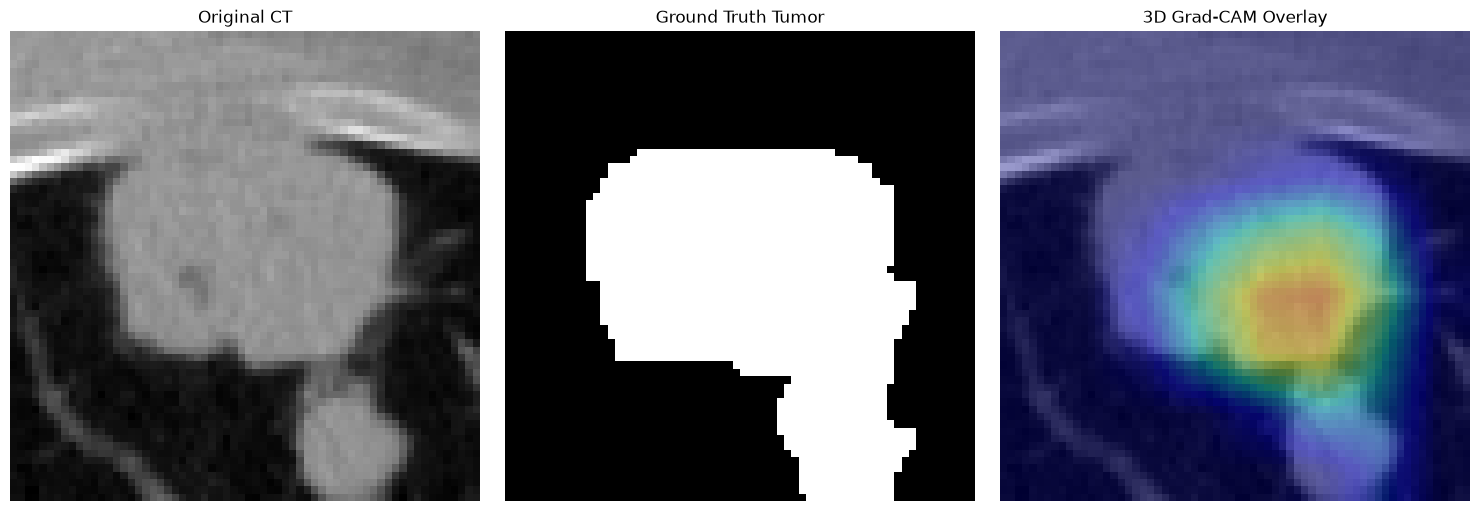

In [50]:
#visualize and save 
ct_np = ct_patch.detach().cpu().numpy()[0, 0]
mask_np = mask_patch.detach().cpu().numpy()[0, 0]

slice_idx = 32

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(ct_np[:, :, slice_idx], cmap="gray")
axes[0].set_title("Original CT")

axes[1].imshow(mask_np[:, :, slice_idx], cmap="gray")
axes[1].set_title("Ground Truth Tumor")

axes[2].imshow(ct_np[:, :, slice_idx], cmap="gray")
axes[2].imshow(
    gradcam_3d[:, :, slice_idx],
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("3D Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

os.makedirs("../outputs/segmentation", exist_ok=True)

plt.savefig(
    "../outputs/segmentation/lung_065_3d_gradcam.png",
    dpi=200,
    bbox_inches="tight"
)

np.save(
    "../outputs/segmentation/lung_065_3d_gradcam.npy",
    gradcam_3d
)

plt.show()

In [52]:
import numpy as np
from pathlib import Path

cache_dir = Path("../processed/segmentation_val_cache")

ct_file = next(cache_dir.glob("*_ct.npy"))
mask_file = cache_dir / ct_file.name.replace("_ct.npy", "_mask.npy")

ct_sample = np.load(ct_file, mmap_mode="r")
mask_sample = np.load(mask_file, mmap_mode="r")

print("Volume:", ct_file.name)
print("CT shape:", ct_sample.shape)
print("Mask shape:", mask_sample.shape)

print("CT range:", float(ct_sample.min()), float(ct_sample.max()))
print("Mask labels:", np.unique(mask_sample))

print("Validation volumes:", len(list(cache_dir.glob("*_ct.npy"))))

Volume: lung_014_ct.npy
CT shape: (380, 380, 295)
Mask shape: (380, 380, 295)
CT range: 0.0 1.0
Mask labels: [0 1]
Validation volumes: 13



Processing lung_014...


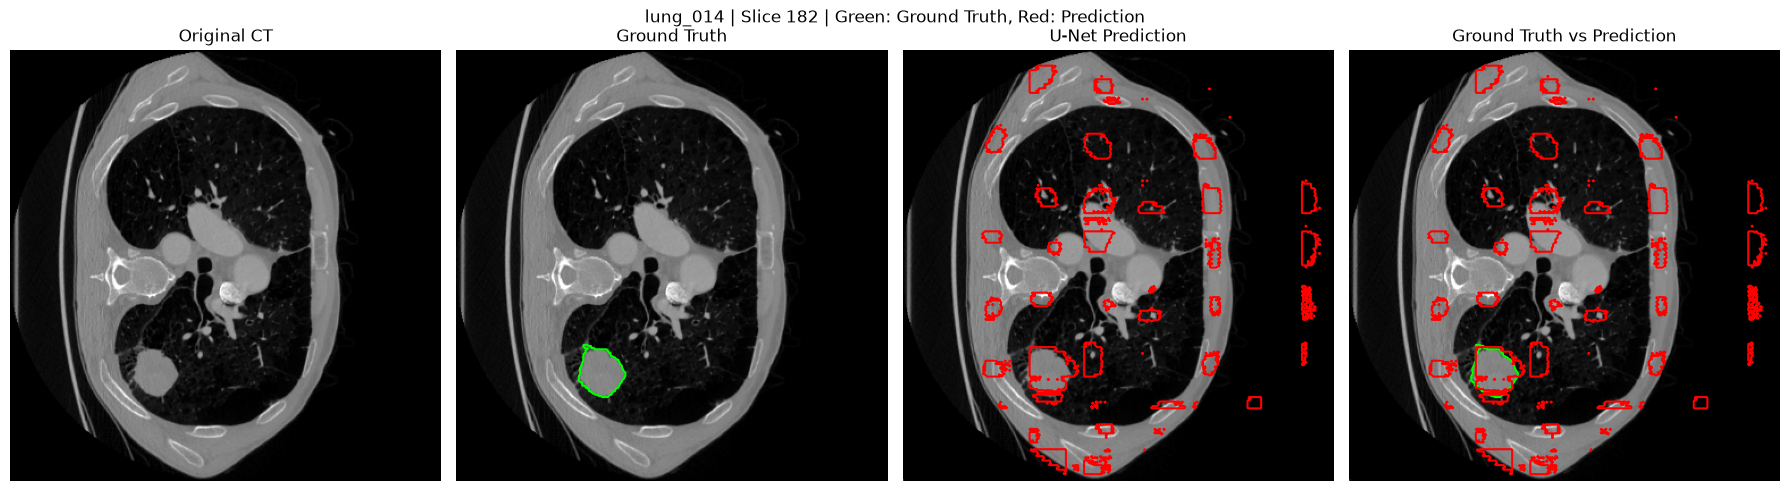

Saved: ..\outputs\segmentation\lung_014_segmentation_results.png
Ground-truth tumor pixels: 1272
Predicted tumor pixels: 8325

Processing lung_058...


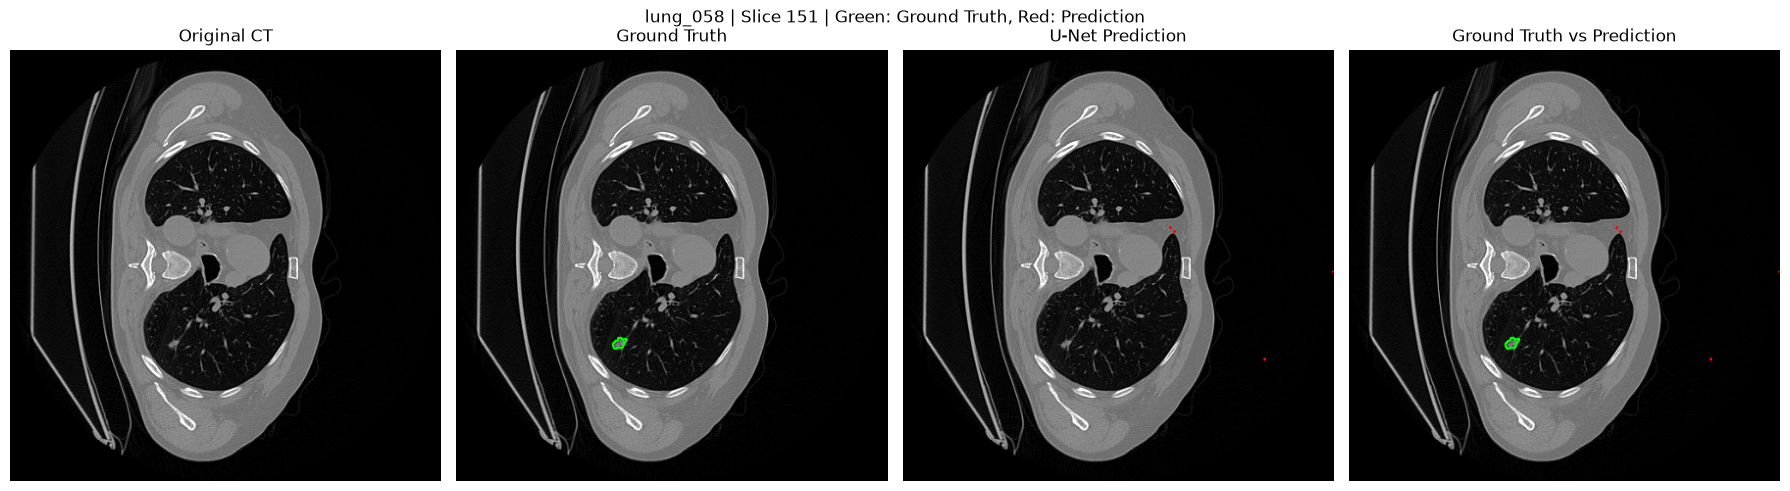

Saved: ..\outputs\segmentation\lung_058_segmentation_results.png
Ground-truth tumor pixels: 97
Predicted tumor pixels: 4

Representative visualizations completed.


In [54]:
#Representative segmentation visualizations
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from monai.inferers import sliding_window_inference

cache_dir = Path("../processed/segmentation_val_cache")
output_dir = Path("../outputs/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

model.eval()

for volume_name in ["lung_014", "lung_058"]:

    print(f"\nProcessing {volume_name}...")

    
    ct_array = np.load(cache_dir / f"{volume_name}_ct.npy").astype(np.float32)
    mask_array = np.load(cache_dir / f"{volume_name}_mask.npy").astype(np.uint8)

    ct_tensor = torch.from_numpy(ct_array).unsqueeze(0).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = sliding_window_inference(
            inputs=ct_tensor,
            roi_size=PATCH_SIZE,
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        prediction = (torch.sigmoid(logits) >= 0.5)

    pred_array = prediction.cpu().numpy()[0, 0]

   
    tumor_per_slice = mask_array.sum(axis=(0, 1))
    slice_idx = int(np.argmax(tumor_per_slice))

    ct_slice = ct_array[:, :, slice_idx]
    gt_slice = mask_array[:, :, slice_idx]
    pred_slice = pred_array[:, :, slice_idx]

    
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(ct_slice, cmap="gray")
    axes[0].set_title("Original CT")

    axes[1].imshow(ct_slice, cmap="gray")
    if gt_slice.any():
        axes[1].contour(gt_slice, levels=[0.5], colors="lime")
    axes[1].set_title("Ground Truth")

    axes[2].imshow(ct_slice, cmap="gray")
    if pred_slice.any():
        axes[2].contour(pred_slice, levels=[0.5], colors="red")
    axes[2].set_title("U-Net Prediction")

    axes[3].imshow(ct_slice, cmap="gray")
    if gt_slice.any():
        axes[3].contour(gt_slice, levels=[0.5], colors="lime")
    if pred_slice.any():
        axes[3].contour(pred_slice, levels=[0.5], colors="red")
    axes[3].set_title("Ground Truth vs Prediction")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{volume_name} | Slice {slice_idx} | "
        "Green: Ground Truth, Red: Prediction"
    )

    plt.tight_layout()

    save_path = output_dir / f"{volume_name}_segmentation_results.png"
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)
    print("Ground-truth tumor pixels:", int(gt_slice.sum()))
    print("Predicted tumor pixels:", int(pred_slice.sum()))

    del ct_tensor, logits, prediction, pred_array
    del ct_array, mask_array

print("\nRepresentative visualizations completed.")

In [55]:
from pathlib import Path

project_root = Path("..")

required_files = [
    "outputs/models/densenet121_chestxray.pth",
    "outputs/models/densenet121_finetuned.pth",
    "outputs/models/3d_unet_lung.pth",
    "outputs/metrics/segmentation_validation_13_volumes.csv",
    "outputs/gradcam/gradcam_overlay.png",
    "outputs/segmentation/lung_014_segmentation_results.png",
    "outputs/segmentation/lung_058_segmentation_results.png",
    "outputs/segmentation/lung_065_3d_gradcam.png",
    "outputs/segmentation/lung_065_3d_gradcam.npy",
]

for file in required_files:
    path = project_root / file
    print(("✓" if path.exists() else "✗"), file)

✓ outputs/models/densenet121_chestxray.pth
✓ outputs/models/densenet121_finetuned.pth
✓ outputs/models/3d_unet_lung.pth
✓ outputs/metrics/segmentation_validation_13_volumes.csv
✓ outputs/gradcam/gradcam_overlay.png
✓ outputs/segmentation/lung_014_segmentation_results.png
✓ outputs/segmentation/lung_058_segmentation_results.png
✓ outputs/segmentation/lung_065_3d_gradcam.png
✓ outputs/segmentation/lung_065_3d_gradcam.npy
